# Step 4 — WS-2 · Q2: *When CSI bids, does it win — and how well-priced?*
Only the **603 projects CSI bid** (117 wins, 19%).

- **Modeled:** P(win | job characteristics). We'll see it has **no signal** —
  that's a result, not a bug (winning is about *price*, not job type).
- **Descriptive overlay (the payoff):** split wins into **well-priced wins** vs
  **bombs**.

> **Bomb = a WIN where CSI bid >14% under 2nd place** (median margin −14.5%) —
> won by leaving money on the table. This is the $22.3M story. 48 of CSI's 117
> wins (41%) are bombs.

In [1]:
from pathlib import Path
import warnings, numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore", category=RuntimeWarning)  # spurious BLAS matmul noise on this machine
pd.set_option("display.width", 140); pd.set_option("display.max_columns", 40)

# --- Absolute paths (edit BASE if you move the project) -----------------------
BASE   = Path("/Users/t/Library/Mobile Documents/com~apple~CloudDocs/00 MSBA + Coding/00_summer 2026/00_CSI_ELP/01_Summer_2026")
MASTER = BASE / "2026-06-03_csi_bid_master.csv"          # raw source (read-only)
OUT    = BASE / "06_sweetspot" / "outputs"               # intermediates + figures
OUT.mkdir(parents=True, exist_ok=True)
MAT = ["MIX_TN","GRADE_CY","BASE_TN","SHLDR_TN","MILL_SY","CRUSH_TN","STOCK_TN"]
print("paths OK |", MASTER.name, "exists:", MASTER.exists())

paths OK | 2026-06-03_csi_bid_master.csv exists: True


In [2]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import cross_val_predict, StratifiedKFold
from sklearn.metrics import roc_auc_score, average_precision_score

base = pd.read_csv(OUT/"2026-06-04_project_base.csv"); arch = pd.read_csv(OUT/"2026-06-04_project_archetypes.csv")
df = base.merge(arch, on="Contract_Id", how="left")
df["log_size"]=np.log10(df["Project_Size_Dollars"].clip(lower=1))
df["BOX_i"]=df["BOX"].astype(int); df["PW_yes"]=(df["PREVAILING_WAGES"]==True).astype(int)
df["PW_unknown"]=df["PREVAILING_WAGES"].isna().astype(int); df["has_quantity_i"]=df["has_quantity"].astype(int)
for p in ["prop_MIX_TN","prop_GRADE_CY","prop_BASE_TN","prop_SHLDR_TN","prop_MILL_SY","prop_STOCK_TN"]: df[p]=df[p].fillna(0.0)
df["State"]=df["State"].fillna("UNK")
bid = df[df["CSI_Participated"]==True].copy(); y=(bid["CSI_Won"]==True).astype(int).values
print("bid:", len(bid), "| wins:", y.sum(), f"({y.mean()*100:.1f}%)")

bid: 603 | wins: 117 (19.4%)


### The win model — and why it (correctly) shows almost no signal

In [3]:
NUM=["log_size","n_mat_types","BOX_i","PW_yes","PW_unknown","prop_MIX_TN","prop_GRADE_CY",
     "prop_BASE_TN","prop_SHLDR_TN","prop_MILL_SY","prop_STOCK_TN","has_quantity_i"]; CAT=["State","rule_archetype"]
pre = ColumnTransformer([("num", Pipeline([("imp",SimpleImputer(strategy="median")),("sc",StandardScaler())]), NUM),
                         ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=10), CAT)])
cv = StratifiedKFold(5, shuffle=True, random_state=42)
for name, clf in [("logistic",LogisticRegression(max_iter=2000,class_weight="balanced")),
                  ("hist_gb", HistGradientBoostingClassifier(random_state=42))]:
    p = cross_val_predict(Pipeline([("pre",pre),("clf",clf)]), bid, y, cv=cv, method="predict_proba")[:,1]
    print(f"{name:9s} ROC-AUC={roc_auc_score(y,p):.3f}  (~0.5 = job features do NOT predict winning)")

logistic  ROC-AUC=0.541  (~0.5 = job features do NOT predict winning)


hist_gb   ROC-AUC=0.511  (~0.5 = job features do NOT predict winning)


**Read this carefully:** AUC ≈ 0.5 means *job characteristics don't tell you
whether CSI wins*. Winning is set by **price** and who else showed up — not the
kind of job. So we do **not** build a margin regression (it would model noise);
we tell the price story descriptively below.

### The gap overlay — where CSI wins WELL vs BOMBS
- **win-well rate** = won at a tight price (Excellent/Acceptable Win) / bids
- **bomb rate** = won but overpaid / bids
- **bomb share of wins** = of the jobs CSI won here, what % were bombs

In [4]:
WIN_WELL={"Excellent Win","Acceptable Win"}
bid["is_win"]=bid["CSI_Won"]==True; bid["is_bomb"]=bid["CSI_Bid_Quality"]=="Bomb"
bid["is_win_well"]=bid["CSI_Bid_Quality"].isin(WIN_WELL)
g = bid.groupby("rule_archetype").agg(n_bid=("is_win","size"),
        win_rate=("is_win","mean"), win_well_rate=("is_win_well","mean"),
        bomb_rate=("is_bomb","mean"), med_size=("Project_Size_Dollars","median"))
g["bomb_share_of_wins"]=bid[bid["is_win"]].groupby("rule_archetype")["is_bomb"].mean()
for c in ["win_rate","win_well_rate","bomb_rate","bomb_share_of_wins"]: g[c]=(g[c]*100).round(1)
g = g.sort_values("win_well_rate", ascending=False); g.to_csv(OUT/"2026-06-04_win_by_archetype.csv"); g

,n_bid,win_rate,win_well_rate,bomb_rate,med_size,bomb_share_of_wins
rule_archetype,,,,,,
Unknown/NoQty,91,22.0,14.3,5.5,4463967.00,25.0
Large Volume,172,19.8,13.4,6.4,3130163.00,32.4
Complex/Messy,108,18.5,13.0,5.6,2906723.50,30.0
Standard Paving,134,20.9,8.2,12.7,793395.85,60.7
Shoulder/Base Only,30,16.7,6.7,6.7,724792.80,40.0
Earthwork Heavy,68,14.7,4.4,10.3,668335.25,70.0


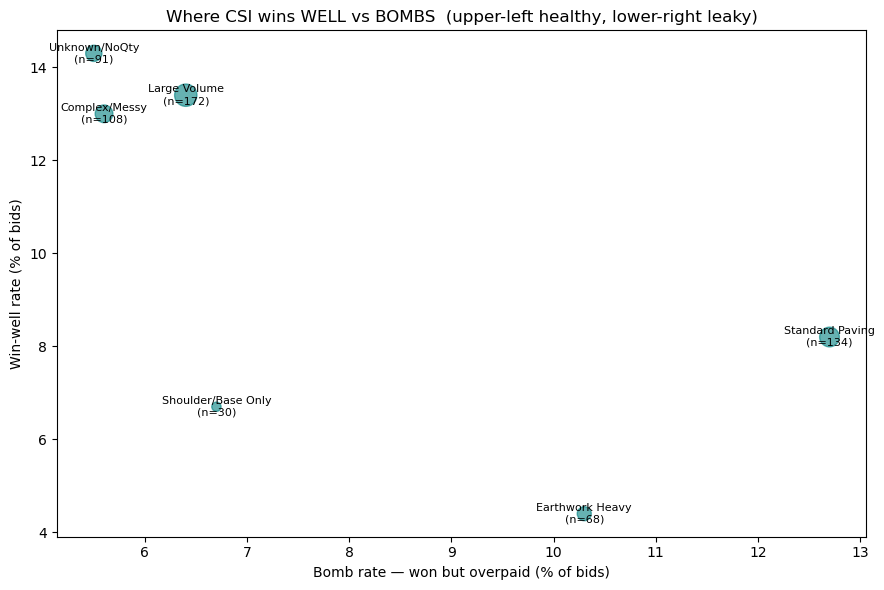

In [5]:
fig, ax = plt.subplots(figsize=(9,6))
ax.scatter(g["bomb_rate"], g["win_well_rate"], s=g["n_bid"]*1.5, alpha=.6, color="teal")
for n,r in g.iterrows(): ax.annotate(f"{n}\n(n={r.n_bid:.0f})",(r.bomb_rate,r.win_well_rate),fontsize=8,ha="center",va="center")
ax.set_xlabel("Bomb rate — won but overpaid (% of bids)"); ax.set_ylabel("Win-well rate (% of bids)")
ax.set_title("Where CSI wins WELL vs BOMBS  (upper-left healthy, lower-right leaky)"); plt.tight_layout(); plt.show()

**Takeaway:** Large Volume & Complex/Messy = win-well, low bomb (healthy).
**Standard Paving (61% of wins are bombs)** and **Earthwork Heavy (70%)** = the
pricing leak.